# Trading con control Monte Carlo on-policy

Q-Learning y SARSA, los dos algoritmos mínimos que pide el enunciado, están en `q_learning.ipynb` y `taller_trader_sarsa.ipynb`. Para ampliar la práctica hemos añadido el control Monte Carlo on-policy con política $\epsilon$-greedy, que vimos en el tema 2. La idea es tener un algoritmo de la otra familia: Q-Learning y SARSA hacen *bootstrapping* (TD), mientras que Monte Carlo espera al final del episodio y usa el retorno real. Así podemos ver en un problema concreto la comparación entre MC y TD del tema 3.

Para poder comparar con Q-Learning hemos usado exactamente su protocolo: el mismo entorno y los mismos generadores, las mismas series de entrenamiento, la misma discretización por cuantiles, las mismas 30 series de validación y 100 de test, y el mismo criterio de convergencia. Ese código común está en `trader_rl.py`.

El notebook sigue este orden: configuración, el algoritmo, qué esperábamos antes de entrenar, ajuste de hiperparámetros, entrenamiento final, test, política aprendida y conclusiones.

## 1. Configuración

In [1]:
import os
import time
import inspect
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed, dump, load

from trader_rl import (GENERATORS, SimpleTradingEnv, Discretizer, MonteCarloAgent, train_monte_carlo,
                       make_series, val_sets, test_sets, evaluate, BASELINES, convergence_episode, summarize,
                       N_SEEDS, FINAL_EPISODES, EVAL_EVERY, SEED_CALIB)

N_JOBS = -1
FIG_DIR = "figuras_montecarlo"
CACHE_DIR = "cache_montecarlo"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

# Si es False y existe la caché, se cargan los resultados en lugar de reentrenar
RECOMPUTE = False

VAL, TEST = val_sets(), test_sets()

COLORS = {"Monte Carlo": "#c2410c", "Q-Learning": "#2a78d6", "Buy & Hold": "#eb6834", "Aleatorio": "#1baf7a",
          "Momentum (regla)": "#eda100", "Contrarian (regla)": "#e87ba4", "Siempre fuera": "#8a8984"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

## 2. El algoritmo

En cada episodio el agente juega la serie entera con su política $\epsilon$-greedy y, cuando termina, recorre el episodio hacia atrás calculando el retorno de cada paso:

$$G_t = R_{t+1} + \gamma G_{t+1}, \qquad Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\,\big[G_t - Q(S_t,A_t)\big].$$

La diferencia con SARSA y Q-Learning está en el objetivo: aquí es el retorno que realmente se ha obtenido, no una estimación a partir de $Q$. Eso quita el sesgo, pero a cambio el objetivo es más ruidoso cuanto mayor es $\gamma$.

Decisiones que hemos tomado:

- La forma de elegir acciones, de desempatar (al azar mientras entrena y a favor de *mantener* al evaluar) y de bajar $\epsilon$ es la misma que en `QLearningAgent`, y también usamos las mismas series de entrenamiento. Así, si sale algo distinto, es por la regla de actualización y no por otro detalle.
- En clase vimos la versión *first-visit*, pero aquí hay muy pocos estados (entre 10 y 40) y 494 pasos por episodio, así que cada par $(s,a)$ aparece muchísimas veces. Con *first-visit* se tirarían casi todos los datos, por eso hemos probado también *every-visit*.
- La versión "de libro" hace la media de todos los retornos ($\alpha = 1/N$). El problema es que la política va cambiando y los retornos de los primeros episodios, casi aleatorios, ya no representan lo que hace el agente. Con un $\alpha$ fijo esos retornos se van olvidando. Hemos metido las dos opciones en la búsqueda.
- $\epsilon$ va bajando hasta $\epsilon_{min}$, igual que en Q-Learning. Al ser on-policy, igual que SARSA, lo que aprende es la mejor política $\epsilon$-greedy; para evaluar usamos la política *greedy*.

Este es el código del agente (está en `trader_rl.py`):

In [2]:
print(inspect.getsource(MonteCarloAgent))

class MonteCarloAgent:
    """Control Monte Carlo on-policy con política ε-greedy (el "On-Policy MC Control" del tema 2).

    Se juega un episodio entero con la política actual y al final se recorre al revés acumulando
    el retorno G <- γG + R_{t+1}, que es lo que se usa como objetivo para Q(S_t, A_t).

    Dos opciones que no vienen fijadas en las diapositivas y que probamos en el ajuste:
    - first_visit: True usa solo la primera visita a cada (s, a) del episodio, como en clase.
      False usa todas (every-visit). Con tan pocos estados cada par se repite muchas veces por
      episodio, así que every-visit aprovecha bastantes más datos.
    - alpha: None hace la media de todos los retornos (α = 1/N, el MC "de libro"). Con un α fijo
      se van olvidando los retornos viejos, que vienen de políticas peores.

    Elegir acción, desempatar y bajar ε se hace igual que en QLearningAgent, para que la única
    diferencia entre los dos sea cómo se actualiza Q.
    """

    def __init__

## 3. Qué esperábamos antes de entrenar

En el tema 3 se dice que MC tiene más varianza que TD porque su objetivo suma todas las recompensas hasta el final. En este problema eso debería notarse mucho: la recompensa de cada paso es casi todo ruido (el precio se mueve entre un 1 % y un 10 % en cada paso y la señal es de décimas de punto).

Para ponerle números hemos calculado, con la política "siempre dentro", cuánto varía $G_t$ según $\gamma$ comparado con lo que varía una sola recompensa. Con $\gamma = 0$ los dos son lo mismo ($G_t = R_{t+1}$), así que MC y TD solo se diferencian cuando $\gamma > 0$.

In [3]:
def returns_std(gen_name, gamma, n_series=40):
    # Desviación típica de G_t con la política 'siempre dentro' (el agente cobra el retorno de cada paso)
    gs, rs = [], []
    for i in range(n_series):
        p = make_series(gen_name, SEED_CALIB + i)
        r = p[6:] / p[5:-1] - 1
        G, out = 0.0, np.empty(len(r))
        for t in range(len(r) - 1, -1, -1):
            G = r[t] + gamma * G
            out[t] = G
        gs.append(out[:-100])          # se descartan los 100 últimos pasos (retorno truncado por el final)
        rs.append(r)
    return np.concatenate(gs).std() / np.concatenate(rs).std()


GAMMAS = [0.0, 0.5, 0.9, 0.99]
var_tab = pd.DataFrame({f"γ = {g}": [returns_std(name, g) for name in GENERATORS] for g in GAMMAS},
                       index=list(GENERATORS))
var_tab.round(2)

,γ = 0.0,γ = 0.5,γ = 0.9,γ = 0.99
Tendencia + ciclo,1.00,1.28,3.32,7.54
Browniano,1.00,1.16,2.31,6.43
Reversión a la media,1.00,1.13,1.94,2.87
Regímenes,1.01,1.17,2.31,6.69


La tabla da cuántas veces más ruidoso es $G_t$ que una recompensa suelta. Con $\gamma = 0.99$ es entre 6 y 7,5 veces más ruidoso, salvo en reversión a la media (2,9), donde los retornos de pasos seguidos tienden a compensarse.

Con TD el objetivo es $R_{t+1} + \gamma \max_a Q(S_{t+1},a)$, que lleva el ruido de una sola recompensa más el de una estimación que ya está promediada. Por eso esperábamos que Monte Carlo necesitara un $\alpha$ más pequeño o un $\gamma$ más bajo que Q-Learning, y que le costara más converger en los mercados donde Q-Learning necesitó $\gamma = 0.99$ (reversión y regímenes). Lo primero se cumplió y lo segundo no, como se ve más abajo.

## 4. Ajuste de hiperparámetros

Igual que en Q-Learning, los hiperparámetros se eligen solo con las series de validación, mirando el log-retorno medio de la política *greedy*. Lo hemos hecho en dos pasos:

1. Una rejilla con $\alpha \in \{0.001, 0.005, 0.01, 0.05, 1/N\}$, $\gamma \in \{0, 0.5, 0.9, 0.99\}$ y 5, 10 o 20 intervalos, con *every-visit*, 1000 episodios y 2 semillas por combinación (480 entrenamientos).
2. Con lo mejor de cada mercado, comparar *first-visit* y *every-visit* y probar $\epsilon_{min} \in \{0.01, 0.05, 0.1\}$ y `decay_frac` $\in \{0.3, 0.6, 0.9\}$, con 3 semillas.

Para el número de episodios usamos 3000, igual que en los otros dos algoritmos; las curvas de la sección 5 muestran que es suficiente.

In [4]:
GRID_EPISODES = 1000
ALPHAS = [0.001, 0.005, 0.01, 0.05, None]      # None = media de todos los retornos (α = 1/N)


def grid_job(gen_name, n_bins, seed, hp, n_episodes=GRID_EPISODES):
    disc = Discretizer(gen_name, {0: n_bins})
    agent, hist = train_monte_carlo(gen_name, disc, n_episodes=n_episodes, seed=seed, **hp)
    res = evaluate(val_sets()[gen_name], lambda i: agent.greedy_policy(disc))
    return {"gen": gen_name, "n_bins": n_bins, "seed": seed, **hp,
            "val_logret": res["log_ret"].mean(), "val_invested": res["invested"].mean(),
            "val_trades": res["trades"].mean(), "time": hist["train_time"]}


grid_path = f"{CACHE_DIR}/grid_alpha_gamma_bins.csv"
if RECOMPUTE or not os.path.exists(grid_path):
    jobs = [(g, nb, sd, {"alpha": a, "gamma": gm})
            for g in GENERATORS for a in ALPHAS for gm in [0.0, 0.5, 0.9, 0.99]
            for nb in [5, 10, 20] for sd in range(2)]
    t0 = time.perf_counter()
    grid = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(grid_job)(*j) for j in jobs))
    print(f"{len(jobs)} entrenamientos en {time.perf_counter() - t0:.0f} s")
    grid.to_csv(grid_path, index=False)
grid = pd.read_csv(grid_path)
grid["alpha"] = grid["alpha"].fillna(-1.0)      # -1 representa α = 1/N en las tablas
grid_mean = grid.groupby(["gen", "alpha", "gamma", "n_bins"], as_index=False)[["val_logret", "val_invested", "val_trades"]].mean()
alpha_label = lambda a: "1/N" if a < 0 else str(a)

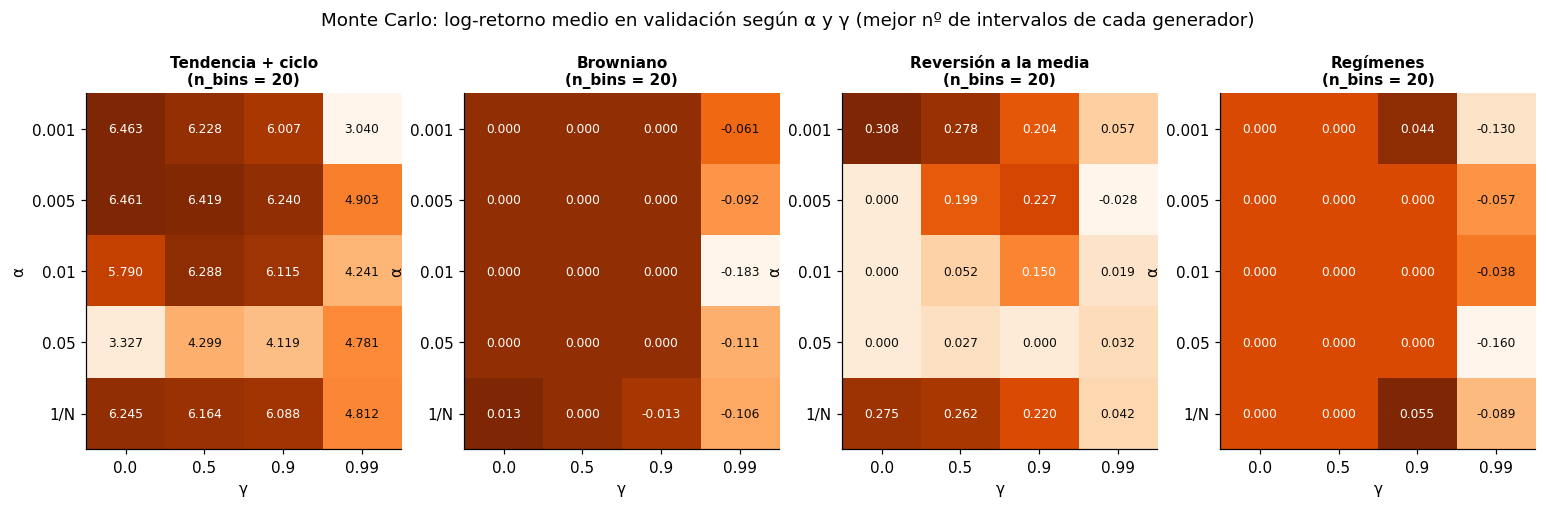

,alpha,gamma,n_bins,val_logret,val_invested,val_trades
gen,,,,,,
Tendencia + ciclo,0.001,0.0,20,6.462771,0.603812,43.250000
Browniano,1/N,0.0,20,0.012571,0.463664,0.500000
Reversión a la media,0.001,0.0,20,0.308000,0.422099,17.300000
Regímenes,1/N,0.9,20,0.055321,0.279184,29.616667


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, g in zip(axes, GENERATORS):
    sub = grid_mean[grid_mean.gen == g]
    best_bins = sub.loc[sub.val_logret.idxmax(), "n_bins"]
    piv = sub[sub.n_bins == best_bins].pivot(index="alpha", columns="gamma", values="val_logret")
    piv = piv.loc[[a for a in [0.001, 0.005, 0.01, 0.05, -1.0] if a in piv.index]]
    im = ax.imshow(piv.values, cmap="Oranges", aspect="auto")
    ax.set_xticks(range(len(piv.columns)), [str(c) for c in piv.columns])
    ax.set_yticks(range(len(piv.index)), [alpha_label(r) for r in piv.index])
    ax.set_xlabel("γ"); ax.set_ylabel("α"); ax.grid(False)
    ax.set_title(f"{g}\n(n_bins = {best_bins})", fontsize=10)
    vmid = np.nanmean(piv.values)
    for (i, j), v in np.ndenumerate(piv.values):
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                color="white" if v > vmid and np.ptp(piv.values) > 0 else "#0b0b0b")
fig.suptitle("Monte Carlo: log-retorno medio en validación según α y γ (mejor nº de intervalos de cada generador)", y=1.06)
plt.savefig(f"{FIG_DIR}/grid_alpha_gamma.png", bbox_inches="tight")
plt.show()

best_rows = grid_mean.loc[grid_mean.groupby("gen").val_logret.idxmax()].set_index("gen").loc[list(GENERATORS)]
best_rows.assign(alpha=best_rows.alpha.map(alpha_label))

Ahora, para cada valor de cada hiperparámetro, el mejor resultado posible con el resto:

In [6]:
sens = {}
for col in ["alpha", "gamma", "n_bins"]:
    t = grid_mean.groupby(["gen", col]).val_logret.max().unstack().loc[list(GENERATORS)]
    if col == "alpha":
        t.columns = [alpha_label(c) for c in t.columns]
    t.columns = pd.MultiIndex.from_product([[col], [str(c) for c in t.columns]])
    sens[col] = t
pd.concat(sens.values(), axis=1).round(3)

alpha                              gamma                \
                        1/N  0.001  0.005   0.01   0.05    0.0    0.5    0.9   
gen                                                                            
Tendencia + ciclo     6.352  6.463  6.461  6.288  6.052  6.463  6.419  6.240   
Browniano             0.013  0.000  0.000  0.000  0.000  0.013  0.000  0.012   
Reversión a la media  0.291  0.308  0.257  0.166  0.109  0.308  0.299  0.257   
Regímenes             0.055  0.044  0.000  0.000  0.000  0.000  0.000  0.055   

                            n_bins                
                       0.99      5     10     20  
gen                                               
Tendencia + ciclo     6.052  6.352  6.395  6.463  
Browniano             0.000  0.012  0.000  0.013  
Reversión a la media  0.170  0.222  0.299  0.308  
Regímenes             0.000  0.000  0.000  0.055

In [7]:
eps_path = f"{CACHE_DIR}/grid_visita_epsilon.csv"
if RECOMPUTE or not os.path.exists(eps_path):
    jobs = []
    for g in GENERATORS:
        b = best_rows.loc[g]
        alpha = None if b.alpha < 0 else float(b.alpha)
        for fv, em, df_ in itertools.product([False, True], [0.01, 0.05, 0.1], [0.3, 0.6, 0.9]):
            for sd in range(3):
                jobs.append((g, int(b.n_bins), sd, {"alpha": alpha, "gamma": float(b.gamma), "first_visit": fv,
                                                    "eps_min": em, "decay_frac": df_}))
    t0 = time.perf_counter()
    eps_grid = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(grid_job)(*j) for j in jobs))
    print(f"{len(jobs)} entrenamientos en {time.perf_counter() - t0:.0f} s")
    eps_grid.to_csv(eps_path, index=False)
eps_grid = pd.read_csv(eps_path)
eps_grid["visita"] = eps_grid.first_visit.map({True: "first-visit", False: "every-visit"})
eps_mean = eps_grid.groupby(["gen", "visita", "eps_min", "decay_frac"], as_index=False).val_logret.mean()

visit_tab = eps_mean.groupby(["gen", "visita"]).val_logret.agg(["max", "mean"]).unstack().loc[list(GENERATORS)]
visit_tab.columns = [f"{v} ({m})" for m, v in visit_tab.columns]
visit_tab.round(3)

,every-visit (max),first-visit (max),every-visit (mean),first-visit (mean)
gen,,,,
Tendencia + ciclo,6.450,6.281,6.347,6.187
Browniano,0.003,0.014,0.000,-0.001
Reversión a la media,0.306,0.255,0.259,0.136
Regímenes,0.050,0.062,0.034,0.009


In [8]:
eps_mean.pivot_table(index="gen", columns=["visita", "eps_min", "decay_frac"], values="val_logret").loc[list(GENERATORS)].round(3)

visita               every-visit                                            \
eps_min                     0.01                 0.05                 0.10   
decay_frac                   0.3    0.6    0.9    0.3    0.6    0.9    0.3   
gen                                                                          
Tendencia + ciclo          6.400  6.450  6.401  6.352  6.334  6.256  6.376   
Browniano                  0.000  0.000  0.000  0.000  0.003  0.000  0.000   
Reversión a la media       0.187  0.166  0.290  0.306  0.271  0.280  0.274   
Regímenes                  0.022  0.010  0.043  0.029  0.050  0.046  0.040   

visita                             first-visit                              \
eps_min                                   0.01                 0.05          
decay_frac              0.6    0.9         0.3    0.6    0.9    0.3    0.6   
gen                                                                          
Tendencia + ciclo     6.306  6.251       6.281  6.270  6.155  6.243  6.153   
Browniano             0.000  0.000      -0.044  0.000  0.007  0.003  0.002   
Reversión a la media  0.263  0.294       0.141  0.031  0.182  0.255  0.074   
Regímenes             0.047  0.023      -0.001 -0.017  0.050  0.019 -0.072   

visita                                            
eps_min                       0.10                
decay_frac              0.9    0.3    0.6    0.9  
gen                                               
Tendencia + ciclo     6.208  6.112  6.061  6.198  
Browniano             0.004  0.006  0.014 -0.004  
Reversión a la media  0.193  0.052  0.118  0.175  
Regímenes            -0.002  0.062  0.016  0.025

In [9]:
best_eps = eps_mean.loc[eps_mean.groupby("gen").val_logret.idxmax()].set_index("gen")
BEST_HP = {}
for g in GENERATORS:
    b = best_rows.loc[g]
    BEST_HP[g] = {"n_bins": int(b.n_bins), "alpha": None if b.alpha < 0 else float(b.alpha), "gamma": float(b.gamma),
                  "first_visit": best_eps.loc[g, "visita"] == "first-visit",
                  "eps_min": float(best_eps.loc[g, "eps_min"]), "decay_frac": float(best_eps.loc[g, "decay_frac"])}
pd.DataFrame(BEST_HP).T

,n_bins,alpha,gamma,first_visit,eps_min,decay_frac
Tendencia + ciclo,20,0.001,0.0,False,0.01,0.6
Browniano,20,None,0.0,True,0.1,0.6
Reversión a la media,20,0.001,0.0,False,0.05,0.3
Regímenes,20,None,0.9,True,0.1,0.3


**Qué sale del ajuste**

- La predicción de la sección 3 se cumple con $\gamma$. Gana $\gamma = 0$ en tendencia + ciclo, reversión y browniano, y cuanto más sube $\gamma$ peor va: en tendencia se pasa de 6,46 a 6,05 y en reversión de 0,31 a 0,17 con $\gamma = 0.99$. Solo en regímenes funciona algo $\gamma = 0.9$ (0,055), y únicamente con $\alpha = 1/N$.
- Con $\gamma = 0$, Monte Carlo y TD persiguen el mismo objetivo, así que en la práctica el ajuste "esquiva" el punto débil de MC. Lo que no esperábamos es que el agente no se vuelve miope del todo. Como la posición forma parte del estado, sale $Q(\text{fuera},\text{comprar}) = E[r \mid b] - c$, $Q(\text{fuera},\text{mantener}) = 0$, $Q(\text{dentro},\text{mantener}) = E[r \mid b]$ y $Q(\text{dentro},\text{vender}) = -c$. Es decir, compra si espera ganar más que la comisión $c$ y vende si espera perder más que ella, y entre medias no hace nada. La histéresis sale sola de la comisión.
- Con $\alpha$, cuanto más pequeño mejor. El mejor valor fijo es el mínimo que probamos, 0,001 (en reversión: 0,308 con 0,001 y 0,109 con 0,05). En los dos mercados casi sin señal gana $\alpha = 1/N$, que es todavía más lento.
- Con 20 intervalos se obtiene lo mejor en los cuatro mercados.
- *Every-visit* gana en media, como esperábamos (0,259 frente a 0,136 en reversión y 6,35 frente a 6,19 en tendencia). En browniano y regímenes el máximo lo da *first-visit*, pero por diferencias tan pequeñas (0,014 frente a 0,003 en browniano) que esa elección no es fiable.
- $\epsilon$ cambia poco las cosas comparado con lo demás.

## 5. Entrenamiento final y curvas de aprendizaje

Con los hiperparámetros elegidos entrenamos 5 semillas por mercado, 3000 episodios cada una y con las mismas series de entrenamiento que Q-Learning. Cada 100 episodios miramos cómo va la política *greedy* en validación. El episodio de convergencia se calcula como en el notebook de Q-Learning: el primero a partir del cual la curva ya no se sale de una banda alrededor de su valor final.

In [10]:
def final_job(gen_name, seed, hp):
    hp = dict(hp)
    disc = Discretizer(gen_name, {0: hp.pop("n_bins")})
    agent, hist = train_monte_carlo(gen_name, disc, n_episodes=FINAL_EPISODES, seed=seed,
                                    val_series=val_sets()[gen_name], eval_every=EVAL_EVERY, **hp)
    return gen_name, seed, agent, disc, hist


final_path = f"{CACHE_DIR}/agentes_finales.joblib"
if RECOMPUTE or not os.path.exists(final_path):
    t0 = time.perf_counter()
    dump(Parallel(n_jobs=N_JOBS)(delayed(final_job)(g, sd, BEST_HP[g]) for g in GENERATORS for sd in range(N_SEEDS)), final_path)
    print(f"Entrenamiento final en {time.perf_counter() - t0:.0f} s")
final_runs = load(final_path)
RUNS = {g: [r for r in final_runs if r[0] == g] for g in GENERATORS}

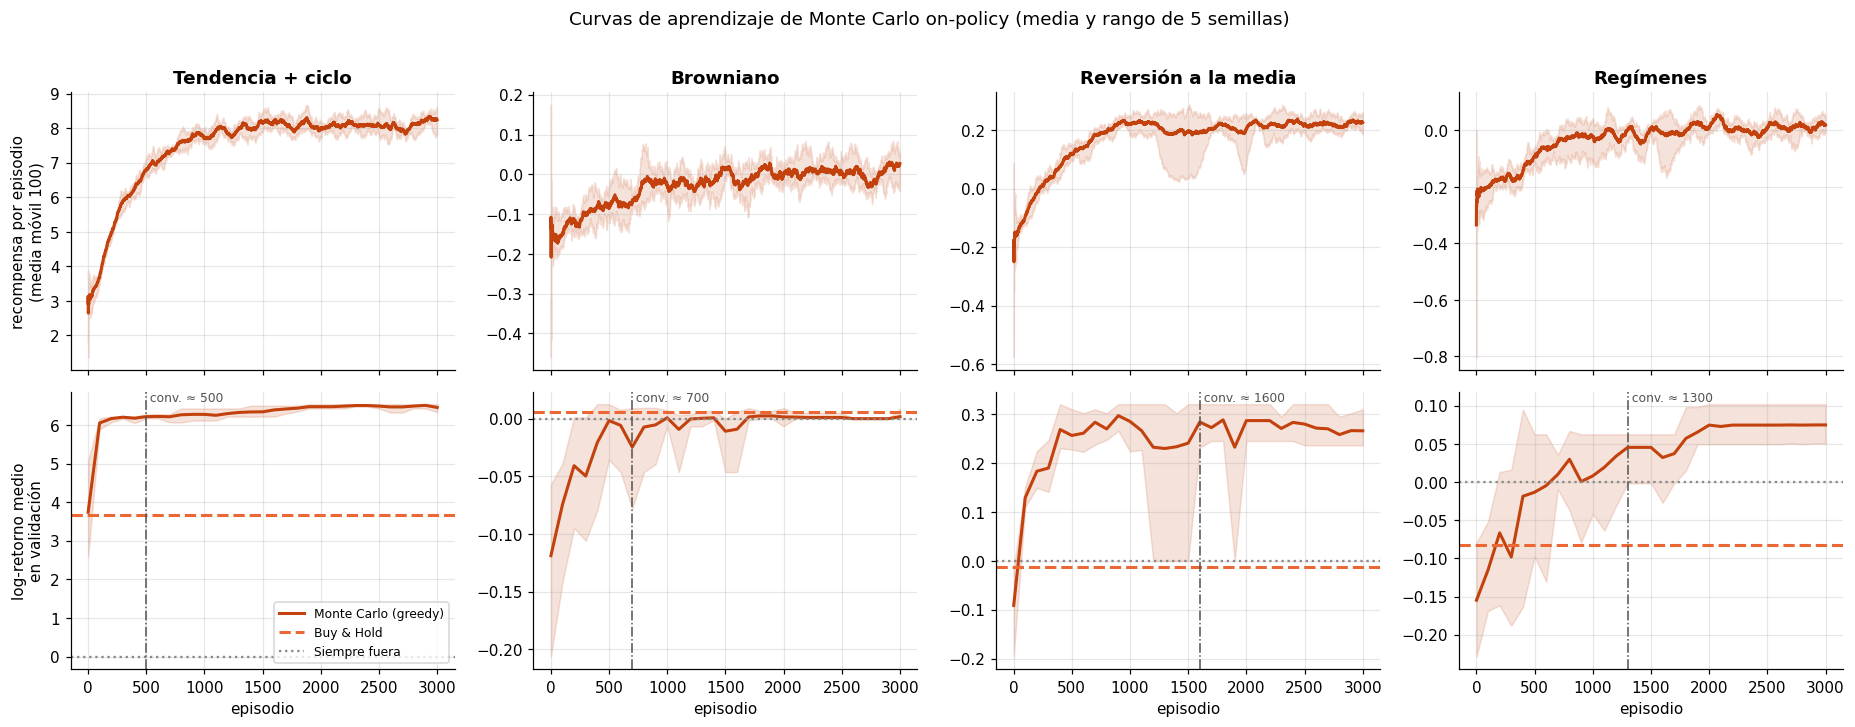

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5), sharex=True)
for j, g in enumerate(GENERATORS):
    runs = RUNS[g]
    rew = np.array([pd.Series(h["ep_reward"]).rolling(100, min_periods=1).mean() for *_, h in runs])
    ax = axes[0, j]
    ax.plot(rew.mean(0), color=COLORS["Monte Carlo"], lw=2)
    ax.fill_between(range(FINAL_EPISODES), rew.min(0), rew.max(0), color=COLORS["Monte Carlo"], alpha=0.15)
    ax.set_title(g)
    ax = axes[1, j]
    vals = np.array([h["val_logret"] for *_, h in runs])
    ep = runs[0][4]["val_ep"]
    ax.plot(ep, vals.mean(0), color=COLORS["Monte Carlo"], lw=2, label="Monte Carlo (greedy)")
    ax.fill_between(ep, vals.min(0), vals.max(0), color=COLORS["Monte Carlo"], alpha=0.15)
    bh = evaluate(VAL[g], BASELINES["Buy & Hold"])["log_ret"].mean()
    ax.axhline(bh, color=COLORS["Buy & Hold"], ls="--", lw=2, label="Buy & Hold")
    ax.axhline(0, color=COLORS["Siempre fuera"], ls=":", lw=1.5, label="Siempre fuera")
    conv = [convergence_episode(h["val_ep"], h["val_logret"]) for *_, h in runs]
    ax.axvline(np.median(conv), color="#52514e", lw=1, ls="-.")
    ax.text(np.median(conv), ax.get_ylim()[1], f" conv. ≈ {int(np.median(conv))}", va="top", fontsize=8, color="#52514e")
    ax.set_xlabel("episodio")
axes[0, 0].set_ylabel("recompensa por episodio\n(media móvil 100)")
axes[1, 0].set_ylabel("log-retorno medio\nen validación")
axes[1, 0].legend(fontsize=8, loc="lower right")
fig.suptitle("Curvas de aprendizaje de Monte Carlo on-policy (media y rango de 5 semillas)", y=1.01)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/curvas_aprendizaje.png", bbox_inches="tight")
plt.show()

## 6. Resultados en test

In [12]:
test_results, rows = {}, []
for g in GENERATORS:
    for name, factory in BASELINES.items():
        res = evaluate(TEST[g], factory)
        test_results[(g, name)] = res
        rows.append(summarize(res, name, g))
    per_seed = [evaluate(TEST[g], lambda i, a=agent, d=disc: a.greedy_policy(d)) for _, _, agent, disc, _ in RUNS[g]]
    res = pd.concat(per_seed, ignore_index=True)
    test_results[(g, "Monte Carlo")] = res
    convs = [convergence_episode(h["val_ep"], h["val_logret"]) for *_, h in RUNS[g]]
    rows.append(summarize(res, "Monte Carlo", g, {
        "Std log-ret. entre semillas": np.std([r["log_ret"].mean() for r in per_seed]),
        "Episodios hasta convergencia": np.median(convs)}))

for r in rows:
    bh = test_results[(r["Generador"], "Buy & Hold")]["log_ret"].values
    mine = test_results[(r["Generador"], r["Agente"])]["log_ret"].values
    r["% series > B&H"] = 100 * np.mean(mine > np.tile(bh, len(mine) // len(bh)))

table = pd.DataFrame(rows).set_index(["Generador", "Agente"])
order = ["Monte Carlo", "Buy & Hold", "Aleatorio", "Siempre fuera", "Momentum (regla)", "Contrarian (regla)"]
table = table.loc[[(g, a) for g in GENERATORS for a in order]]
main_cols = ["Log-ret. medio", "Ret. geométrico (%)", "Ret. mediano (%)", "% series > B&H", "Sharpe",
             "Max DD (%)", "Operaciones", "% tiempo invertido"]
table[main_cols].round(3)

Log-ret. medio  Ret. geométrico (%)  \
Generador            Agente                                                    
Tendencia + ciclo    Monte Carlo                  6.522            67892.203   
                     Buy & Hold                   3.316             2655.989   
                     Aleatorio                    1.558              375.064   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)             6.105            44704.614   
                     Contrarian (regla)          -2.973              -94.883   
Browniano            Monte Carlo                 -0.012               -1.236   
                     Buy & Hold                  -0.062               -6.039   
                     Aleatorio                   -0.187              -17.058   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.141              -13.135   
                     Contrarian (regla)          -0.159              -14.695   
Reversión a la media Monte Carlo                  0.238               26.917   
                     Buy & Hold                  -0.005               -0.484   
                     Aleatorio                   -0.169              -15.581   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.324              -27.707   
                     Contrarian (regla)           0.069                7.096   
Regímenes            Monte Carlo                  0.031                3.125   
                     Buy & Hold                  -0.128              -11.981   
                     Aleatorio                   -0.220              -19.734   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.126              -11.877   
                     Contrarian (regla)          -0.233              -20.796   

                                         Ret. mediano (%)  % series > B&H  \
Generador            Agente                                                 
Tendencia + ciclo    Monte Carlo                72443.323            97.4   
                     Buy & Hold                  2960.313             0.0   
                     Aleatorio                    443.073            19.0   
                     Siempre fuera                  0.000            11.0   
                     Momentum (regla)           46290.789            96.0   
                     Contrarian (regla)           -95.150             0.0   
Browniano            Monte Carlo                    0.000            48.8   
                     Buy & Hold                    -0.945             0.0   
                     Aleatorio                    -16.443            37.0   
                     Siempre fuera                  0.000            51.0   
                     Momentum (regla)             -10.719            38.0   
                     Contrarian (regla)           -14.360            38.0   
Reversión a la media Monte Carlo                   27.019            90.0   
                     Buy & Hold                    -1.211             0.0   
                     Aleatorio                    -16.687            24.0   
                     Siempre fuera                  0.000            58.0   
                     Momentum (regla)             -27.817            11.0   
                     Contrarian (regla)             9.999            62.0   
Regímenes            Monte Carlo                    1.463            67.0   
                     Buy & Hold                    -7.940             0.0   
                     Aleatorio                    -16.313            36.0   
                     Siempre fuera                  0.000            58.0   
                     Momentum (regla)             -14.092            50.0   
                     Contrarian (re

In [13]:
table.xs("Monte Carlo", level="Agente")[["Std log-ret. entre semillas", "Episodios hasta convergencia"]].round(3)

,Std log-ret. entre semillas,Episodios hasta convergencia
Generador,,
Tendencia + ciclo,0.039,500.0
Browniano,0.025,700.0
Reversión a la media,0.015,1600.0
Regímenes,0.011,1300.0


**Comentarios sobre el test.** Los *baselines* dan exactamente lo mismo que en `q_learning.ipynb`, lo que confirma que estamos usando las mismas series.

- **Tendencia + ciclo:** log-retorno de 6,52, frente a 3,32 de *buy & hold* y 6,11 de la regla de *momentum*. Gana a *buy & hold* en el 97 % de las series y opera 39 veces por episodio, cuando la regla opera 93. Converge en unos 500 episodios.
- **Browniano:** pierde un 1,2 %. Es mejor que *buy & hold* (−6 %) y que el aleatorio (−17 %), pero peor que no hacer nada. Casi nunca compra (0,2 operaciones por episodio), pero cuando compra ya no vende y acaba pasando el 19 % del tiempo dentro. Con $\gamma = 0$, vender cuesta la comisión seguro y mantener vale más o menos cero, así que una vez dentro se queda. Además, los hiperparámetros de este mercado se eligieron por una diferencia en validación que era ruido.
- **Reversión a la media:** gana un 26,9 % (log-retorno 0,238), frente al −0,5 % de *buy & hold* y el +7,1 % de la regla *contrarian*. Supera a *buy & hold* en el 90 % de las series, con un Sharpe de 0,75 y un *drawdown* del 16 % (26 % en *buy & hold*), y opera 21 veces por episodio. Converge en unos 1600 episodios.
- **Regímenes:** gana un 3,1 % cuando *buy & hold* pierde un 12 %, y le gana en el 67 % de las series. Converge en unos 1300 episodios.

Las 5 semillas salen muy parecidas entre sí (desviación de 0,011 a 0,039), cosa lógica con un $\alpha$ tan pequeño.

## 7. Política aprendida

El mismo gráfico que en el notebook de Q-Learning: para cada intervalo de tendencia, qué fracción de las 5 semillas acaba invertida después de actuar. Estando fuera eso significa comprar; estando dentro, no vender.

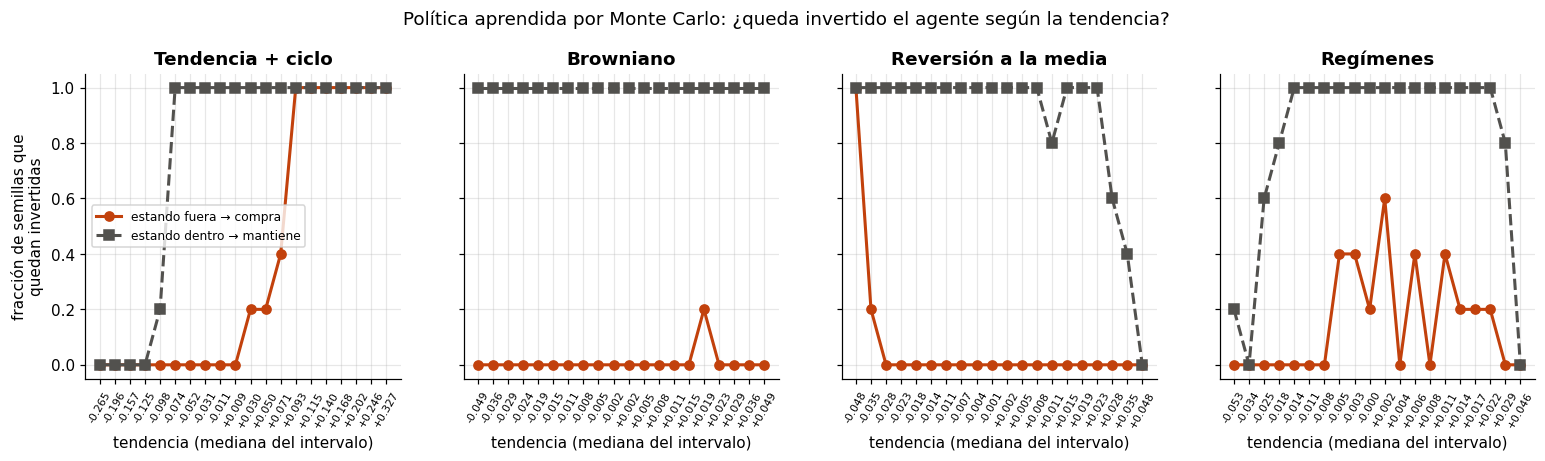

In [14]:
def invested_after(agent, n_bins):
    out = np.zeros((2, n_bins))
    for b in range(n_bins):
        for pos in (0, 1):
            a = agent.greedy(b * 2 + pos)
            out[pos, b] = (a == 2) if pos == 0 else (a != 0)
    return out


def trend_series(p):
    out = np.empty(len(p) - 6)
    for i, k in enumerate(range(5, len(p) - 1)):
        w = p[k - 5:k + 1]
        out[i] = np.clip((w[-1] - w.mean()) / w.mean(), -1, 1)
    return out


fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, g in zip(axes, GENERATORS):
    nb = BEST_HP[g]["n_bins"]
    mats = np.array([invested_after(agent, nb) for _, _, agent, _, _ in RUNS[g]])
    trs = np.concatenate([trend_series(make_series(g, SEED_CALIB + i)) for i in range(40)])
    edges = np.concatenate([[trs.min()], RUNS[g][0][3].edges[0], [trs.max()]])
    centers = [np.median(trs[(trs >= lo) & (trs <= hi)]) for lo, hi in zip(edges[:-1], edges[1:])]
    x = np.arange(nb)
    ax.plot(x, mats[:, 0].mean(0), "o-", color=COLORS["Monte Carlo"], lw=2, ms=6, label="estando fuera → compra")
    ax.plot(x, mats[:, 1].mean(0), "s--", color="#52514e", lw=2, ms=6, label="estando dentro → mantiene")
    ax.set_xticks(x, [f"{c:+.3f}" for c in centers], rotation=60, fontsize=7)
    ax.set_xlabel("tendencia (mediana del intervalo)")
    ax.set_title(g)
    ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel("fracción de semillas que\nquedan invertidas")
axes[0].legend(fontsize=8, loc="center left")
fig.suptitle("Política aprendida por Monte Carlo: ¿queda invertido el agente según la tendencia?", y=1.04)
plt.savefig(f"{FIG_DIR}/politicas.png", bbox_inches="tight")
plt.show()

**Cómo leer las políticas**

- **Tendencia + ciclo:** *momentum* con histéresis. Solo compra cuando la tendencia es claramente positiva (a partir de +0,07, más o menos) y, una vez dentro, aguanta hasta que es claramente negativa (por debajo de −0,10). Es la banda de la sección 4, y es más ancha que la de Q-Learning, por eso opera menos.
- **Browniano:** casi nunca compra, pero si está dentro mantiene en todo el rango, y de ahí el 19 % de tiempo invertido.
- **Reversión a la media:** *contrarian*. Solo compra en el intervalo de tendencia más negativo y mantiene hasta que la tendencia se pone claramente positiva (+0,03, más o menos). Compra en los valles y vende cuando el precio se ha recuperado.
- **Regímenes:** sale una meseta, igual que en Q-Learning. Dentro, mantiene con tendencias normales y vende cuando hay movimientos muy bruscos; fuera, compra poco y cada semilla en sitios distintos, como corresponde a una señal tan débil.

## 8. Guardar resultados

Guardamos la tabla en CSV y los agentes en `cache_montecarlo/`. La comparación con Q-Learning y SARSA está en `comparativa.ipynb`.

In [15]:
table.astype(float).round(4).to_csv("resultados_montecarlo.csv", encoding="utf-8-sig")
pd.DataFrame(BEST_HP).T.to_csv("hiperparametros_montecarlo.csv", encoding="utf-8-sig")
print("Guardado: resultados_montecarlo.csv, hiperparametros_montecarlo.csv y figuras en", FIG_DIR)

Guardado: resultados_montecarlo.csv, hiperparametros_montecarlo.csv y figuras en figuras_montecarlo


## Conclusiones

1. El control Monte Carlo on-policy funciona bien en este problema: gana a *buy & hold* y al agente aleatorio en los cuatro mercados y aprende lo que cabía esperar en cada uno (*momentum*, *contrarian* y salir ante movimientos bruscos).
2. Su punto débil es el que vimos en clase, la varianza del retorno completo. Con $\gamma = 0.99$ el objetivo es entre 3 y 7,5 veces más ruidoso y el rendimiento cae. El ajuste lo resuelve eligiendo $\gamma = 0$, y en ese caso el objetivo de Monte Carlo es el mismo que el de TD.
3. Cuando hay señal, *every-visit* y un $\alpha$ fijo y pequeño funcionan mejor que la versión de clase: se aprovechan todas las visitas y se olvidan los retornos de políticas antiguas.
4. En `comparativa.ipynb` comprobamos que Q-Learning con estos mismos hiperparámetros saca prácticamente lo mismo. O sea, la ventaja de Monte Carlo en la tabla viene sobre todo de usar $\alpha = 0.001$, un valor que no estaba en la rejilla de Q-Learning, y no de la regla de actualización.
5. Limitaciones: en browniano los hiperparámetros se eligieron sobre ruido y eso cuesta un 1,2 %. Además, Monte Carlo solo aprende al final de cada episodio. Aquí da igual porque los episodios terminan (494 pasos), pero no serviría para una tarea continua.